# A/B-тест формы оплаты ЖКХ

**Анализ продуктового кейса Т-Банка · 1–30 апреля 2024 года**

Команда платежей проверяет гипотезу: форма с упрощённым вводом реквизитов повышает долю успешных оплат ЖКХ. Целевая метрика — **конверсия из открытия формы в успешную оплату**.

**Краткий результат.** В группе B успешно завершились **64,40%** попыток против **49,77%** в группе A. Разница — **+14,63 процентного пункта**; 95%-й доверительный интервал с учётом повторных попыток клиентов — **[+10,96; +18,25] п. п.**

**Рекомендация:** если B — вариант с новой формой, её стоит выводить в продакшен постепенно, контролируя ошибки оплаты и обращения в поддержку. В условии кейса не приведено соответствие букв A/B вариантам интерфейса, поэтому перед запуском его необходимо подтвердить.

Ниже — проверка качества данных, расчёт метрик и статистическое обоснование решения. Исходный Excel предоставлен в составе учебного кейса.


## 1. Данные и единица наблюдения

Excel-файл содержит два листа: **«Пользователи»** (группа эксперимента, возраст, город, устройство) и **«Платежи»** (попытки оплаты с датами прохождения четырёх этапов).

Группы назначались **клиентам**, однако один клиент мог несколько раз открыть форму оплаты. Поэтому основную конверсию считаем по попыткам, а статистические выводы делаем с учётом повторных наблюдений внутри клиента.


In [1]:

import pandas as pd

file_path = "data/ab_test_jkh.xlsx"

users = pd.read_excel(file_path, sheet_name="Пользователи")
payments = pd.read_excel(file_path, sheet_name="Платежи")

print("Пользователи:", users.shape)
print("Платежи:", payments.shape)


Пользователи: (1504, 5)
Платежи: (2661, 7)


In [2]:
users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [3]:
payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


## 2. Проверка качества данных

Сначала проверим типы полей, пропуски и уникальность идентификаторов. В таблице платежей пустое время последующего этапа не обязательно означает ошибку: пользователь мог просто не дойти до него.

### 2.1. Типы данных и пропуски


In [4]:

print("Информация о пользователях:")
users.info()

print("\nИнформация о платежах:")
payments.info()


Информация о пользователях:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB

Информация о платежах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 

In [5]:

print("Пропуски в таблице пользователей:")
print(users.isna().sum())

print("\nПропуски в таблице платежей:")
print(payments.isna().sum())


Пропуски в таблице пользователей:
user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

Пропуски в таблице платежей:
payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64


Из **1 504** записей о клиентах у одной отсутствует группа, ещё у одной — город. В **2 661** попытке оплаты один раз отсутствует `user_id`. Даты открытия формы заполнены во всех попытках, а последующие этапы — не во всех: ввод реквизитов — **2 256**, подтверждение — **1 719**, успешная оплата — **1 522**.

Такие пропуски в этапах воронки не заполняем искусственно: иначе конверсия была бы искажена.


### 2.2. Баланс групп и дубликаты


In [6]:

print("Пользователи по группам:")
print(users["group"].value_counts(dropna=False))

print("\nПлатежи по группам:")
print(payments["group"].value_counts(dropna=False))

print("\nДубликаты user_id:")
print(users["user_id"].duplicated().sum())

print("\nДубликаты payment_id:")
print(payments["payment_id"].duplicated().sum())


Пользователи по группам:
group
A      752
B      751
NaN      1
Name: count, dtype: int64

Платежи по группам:
group
B    1352
A    1309
Name: count, dtype: int64

Дубликаты user_id:
0

Дубликаты payment_id:
0


В исходной таблице **752** клиента группы A и **751** группы B; у ещё одного группа не задана. Идентификаторы клиентов и платежей уникальны. На первый взгляд распределение клиентов между группами близко к 50/50, но правильность назначения групп для каждого платежа нужно проверить отдельно.


### 2.3. Сопоставление платежей с клиентами

Присоединим к каждой попытке группу из таблицы клиентов. Это позволит обнаружить платежи без известного пользователя и записи с противоречивой группой.


In [7]:

# Добавляем к платежам группу из таблицы пользователей
payments_check = payments.merge(
    users[["user_id", "group"]],
    on="user_id",
    how="left",
    suffixes=("_payment", "_user")
)

# Проверяем отсутствующие идентификаторы
print("Платежи без user_id:")
print(payments_check["user_id"].isna().sum())

# Находим несовпадения групп
group_mismatch = payments_check[
    payments_check["group_user"].notna()
    & (payments_check["group_payment"] != payments_check["group_user"])
]

print("\nПлатежи с несовпадением групп:")
print(len(group_mismatch))

group_mismatch[["payment_id", "user_id", "group_payment", "group_user"]]


Платежи без user_id:
1

Платежи с несовпадением групп:
1


,payment_id,user_id,group_payment,group_user
2659,99002,1010.0,B,A


In [8]:

print("Пользователи без группы:")
display(users[users["group"].isna()])

print("\nПлатежи без известной группы пользователя:")
display(
    payments_check[
        payments_check["group_user"].isna()
    ][["payment_id", "user_id", "group_payment", "group_user"]]
)


Пользователи без группы:


,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios



Платежи без известной группы пользователя:


,payment_id,user_id,group_payment,group_user
2660,99003,NaN,A,NaN


Обнаружены две проблемные попытки:

- **`99003`** — нет `user_id`, проверить группу клиента невозможно;
- **`99002`** — платёж записан в B, но клиент `1010` закреплён за A.

Также у клиента `9001` отсутствует группа, однако связанных с ним платежей нет. Ниже исключим обе спорные попытки из основного расчёта; отдельно проверим, меняется ли результат, если вернуть `99002` в группу A по данным клиентов.


### 2.4. Аномалии в характеристиках пользователей


In [9]:

# Проверяем аномальный возраст
invalid_age = users[
    (users["age"] < 0) | (users["age"] > 120)
]

print("Пользователи с аномальным возрастом:")
display(invalid_age)

# Проверяем пропуски города
missing_city = users[users["city"].isna()]

print("Пользователи без города:")
display(missing_city)


Пользователи с аномальным возрастом:


,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


Пользователи без города:


,user_id,group,age,city,device_type
1503,9004,A,30,NaN,android


Обнаружены два некорректных возраста (**−5** и **150** лет) и один пропуск города. Эти поля не участвуют в расчёте общей конверсии, поэтому удалять клиентов и их платежи из-за них не нужно. Для анализа по возрастам или городам значения потребовали бы отдельной обработки.


### 2.5. Проверка порядка этапов

У успешной оплаты должны быть заполнены предыдущие этапы, а временные отметки должны идти последовательно.


In [10]:

# Проверяем пропущенные предыдущие этапы
wrong_step3 = (
    payments["step3_confirmed"].notna()
    & payments["step2_entered"].isna()
)

wrong_step4 = (
    payments["step4_success"].notna()
    & payments["step3_confirmed"].isna()
)

print("Подтверждение без ввода реквизитов:", wrong_step3.sum())
print("Успешная оплата без подтверждения:", wrong_step4.sum())

# Проверяем порядок времени
wrong_time = (
    (payments["step2_entered"] < payments["step1_opened"])
    | (payments["step3_confirmed"] < payments["step2_entered"])
    | (payments["step4_success"] < payments["step3_confirmed"])
)

print("Нарушения порядка времени:", wrong_time.sum())


Подтверждение без ввода реквизитов: 0
Успешная оплата без подтверждения: 0
Нарушения порядка времени: 0


Нарушений не найдено: **0** подтверждений без ввода реквизитов, **0** успешных оплат без подтверждения и **0** случаев обратного порядка времени. Поэтому отсутствие дат следующих этапов в этих данных трактуем как недостижение соответствующего шага.


## 3. Подготовка выборки

Основной анализ проводим только по платежам с известной и согласованной группой клиента. Исключаем попытку без идентификатора пользователя и попытку с конфликтующими группами. Исходные таблицы не изменяем, незавершённые оплаты сохраняем.


In [11]:

# Оставляем платежи с известной и совпадающей группой
payments_clean = payments_check[
    payments_check["group_user"].isin(["A", "B"])
    & (payments_check["group_payment"] == payments_check["group_user"])
].copy()

print("Исходных платежей:", len(payments))
print("После очистки:", len(payments_clean))
print("Исключено:", len(payments) - len(payments_clean))

print("\nПлатежи по группам после очистки:")
print(payments_clean["group_user"].value_counts())


Исходных платежей: 2661
После очистки: 2659
Исключено: 2

Платежи по группам после очистки:
group_user
B    1351
A    1308
Name: count, dtype: int64


После очистки осталось **2 659** попыток: **1 308** в A и **1 351** в B (исключены 2 записи из 2 661). Проверим, что все открытия формы относятся к периоду эксперимента.


In [12]:

# Границы эксперимента
start_date = pd.Timestamp("2024-04-01")
end_date = pd.Timestamp("2024-05-01")

# Ищем платежи вне периода теста
outside_period = payments_clean[
    (payments_clean["step1_opened"] < start_date)
    | (payments_clean["step1_opened"] >= end_date)
]

print("Самая ранняя дата:", payments_clean["step1_opened"].min())
print("Самая поздняя дата:", payments_clean["step1_opened"].max())
print("Платежей вне периода теста:", len(outside_period))


Самая ранняя дата: 2024-04-01 00:19:00
Самая поздняя дата: 2024-04-30 23:17:00
Платежей вне периода теста: 0


Все попытки относятся к **1–30 апреля 2024 года**; за пределами тестового периода записей нет. Дополнительная фильтрация по датам не требуется.


## 4. Результаты эксперимента

### 4.1. Основная метрика: конверсия по попыткам

Конверсия = количество успешных оплат / количество открытий формы × 100%. Это показатель **на уровне попыток**, а не уникальных клиентов.


In [13]:

funnel = payments_clean.groupby("group_user").agg(
    opened=("step1_opened", "count"),
    entered=("step2_entered", "count"),
    confirmed=("step3_confirmed", "count"),
    success=("step4_success", "count")
)

funnel["conversion_pct"] = (
    funnel["success"] / funnel["opened"] * 100
).round(2)

display(funnel)


,opened,entered,confirmed,success,conversion_pct
group_user,,,,,
A,1308,1061,758,651,49.77
B,1351,1194,960,870,64.40


| Показатель | A | B |
|---|---:|---:|
| Открытия формы | 1 308 | 1 351 |
| Успешные оплаты | 651 | 870 |
| Конверсия | **49,77%** | **64,40%** |

Разница **B − A = +14,63 п. п.** По одной этой разнице нельзя судить о статистической значимости, но она достаточно велика, чтобы разобраться, на каких этапах расходится воронка.


### 4.2. Переходы между этапами

Для каждого шага отдельно посчитаем долю попыток, дошедших до следующего шага. Здесь знаменатель — число попыток на **предыдущем** этапе.


In [14]:

# Рассчитываем конверсию между этапами
step_conversion = pd.DataFrame(index=funnel.index)

step_conversion["Шаг 1 → 2"] = (
    funnel["entered"] / funnel["opened"] * 100
).round(2)

step_conversion["Шаг 2 → 3"] = (
    funnel["confirmed"] / funnel["entered"] * 100
).round(2)

step_conversion["Шаг 3 → 4"] = (
    funnel["success"] / funnel["confirmed"] * 100
).round(2)

display(step_conversion)


,Шаг 1 → 2,Шаг 2 → 3,Шаг 3 → 4
group_user,,,
A,81.12,71.44,85.88
B,88.38,80.40,90.62


Наибольшее различие между группами — на переходе **«ввод реквизитов → подтверждение»**: **80,40%** в B против **71,44%** в A, или **+8,96 п. п.** Переход «открытие → ввод» также лучше в B (**+7,26 п. п.**), как и «подтверждение → успешная оплата» (**+4,74 п. п.**).

Это согласуется с гипотезой об удобстве формы, но само по себе не доказывает, что улучшение связано именно с автозаполнением: у нас нет отдельных данных об использовании этой функции.


### 4.3. Прохождение воронки от первого шага

На графике ниже для каждого этапа показана доля от **всех открытий формы**. Поэтому начало воронки у обеих групп равно 100%, а финальные точки совпадают с основной конверсией.


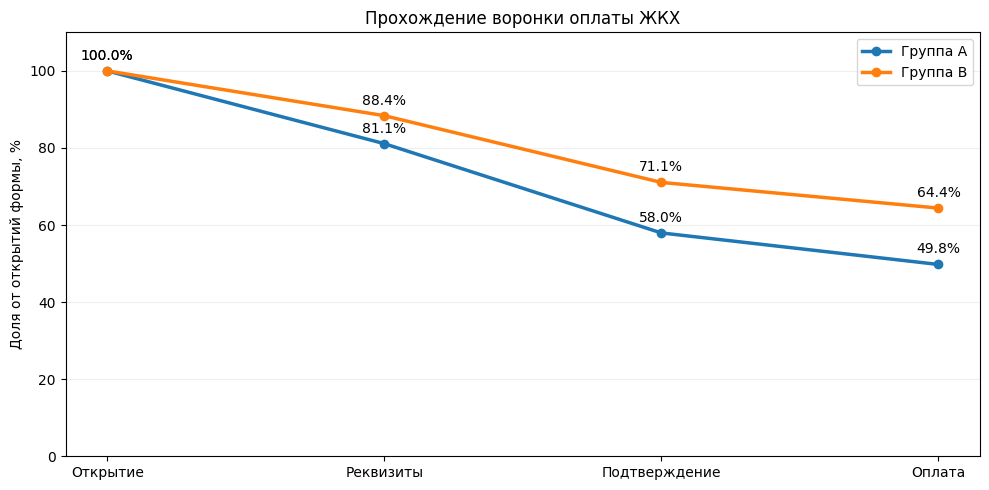

In [15]:
import matplotlib.pyplot as plt

from pathlib import Path

stages = ["Открытие", "Реквизиты", "Подтверждение", "Оплата"]
columns = ["opened", "entered", "confirmed", "success"]

fig, ax = plt.subplots(figsize=(10, 5))

for group in ["A", "B"]:
    values = (
        funnel.loc[group, columns]
        / funnel.loc[group, "opened"] * 100
    )

    ax.plot(stages, values, marker="o", linewidth=2.5, label=f"Группа {group}")

    for x, y in zip(stages, values):
        ax.annotate(
            f"{y:.1f}%",
            (x, y),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center"
        )

ax.set_title("Прохождение воронки оплаты ЖКХ")
ax.set_ylabel("Доля от открытий формы, %")
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Сохраняем график для будущего PDF
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/payment_funnel.png", dpi=200, bbox_inches="tight")

plt.show()


Разрыв между группами становится заметнее по мере прохождения воронки. На последнем этапе до успешной оплаты доходят **64,40%** попыток B и **49,77%** попыток A.


### 4.4. Дополнительная метрика: доля клиентов с успешной оплатой

Чтобы учесть повторные попытки, отдельно посчитаем долю **активных клиентов** (которые хотя бы раз открыли форму), совершивших хотя бы одну успешную оплату. Этот показатель отвечает на другой вопрос и не заменяет основную конверсию.


In [16]:

# Рассчитываем показатели для каждого пользователя
user_stats = payments_clean.groupby(
    ["group_user", "user_id"]
).agg(
    attempts=("payment_id", "count"),
    has_success=("step4_success", lambda x: x.notna().any())
).reset_index()

display(user_stats.head())


,group_user,user_id,attempts,has_success
0,A,1001.0,1,False
1,A,1002.0,1,False
2,A,1003.0,1,False
3,A,1004.0,3,True
4,A,1005.0,2,True


In [17]:

# Считаем долю пользователей с успешной оплатой
user_conversion = user_stats.groupby("group_user").agg(
    users=("user_id", "count"),
    successful_users=("has_success", "sum"),
    avg_attempts=("attempts", "mean")
)

user_conversion["conversion_pct"] = (
    user_conversion["successful_users"]
    / user_conversion["users"] * 100
).round(2)

user_conversion["avg_attempts"] = (
    user_conversion["avg_attempts"].round(2)
)

display(user_conversion)


,users,successful_users,avg_attempts,conversion_pct
group_user,,,,
A,751,493,1.74,65.65
B,750,603,1.80,80.40


| Показатель | A | B |
|---|---:|---:|
| Клиенты с попытками оплаты | 751 | 750 |
| Клиенты хотя бы с одной успешной оплатой | 493 | 603 |
| Доля клиентов с успешной оплатой | **65,65%** | **80,40%** |
| Среднее число попыток на клиента | 1,74 | 1,80 |

По пользовательской метрике разница также в пользу B: **+14,75 п. п.** В каждой из групп был ещё один назначенный клиент без попыток, поэтому в этот расчёт они не вошли. Это дополнительный анализ активных клиентов, а не показатель среди всех рандомизированных пользователей.


### 4.5. Сравнение двух метрик

Ниже две метрики представлены рядом. Их знаменатели различаются: **попытки оплаты** и **уникальные активные клиенты**.


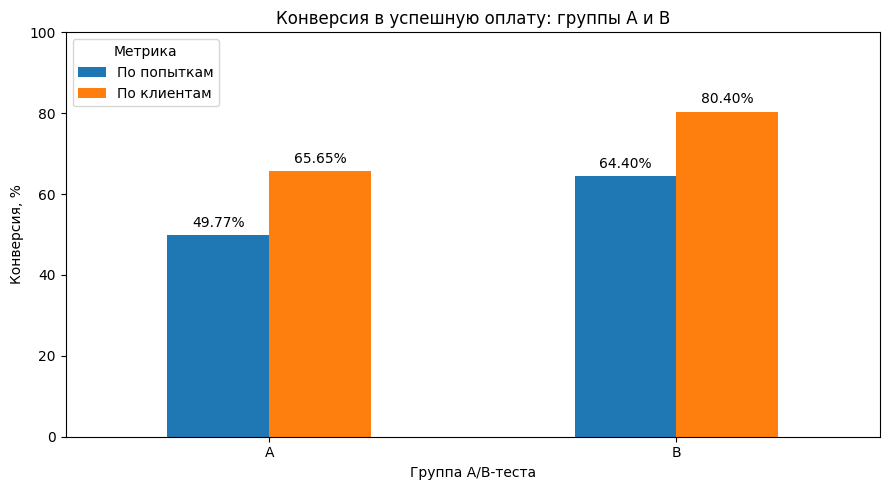

In [18]:
import matplotlib.pyplot as plt

# Подготавливаем данные для графика
comparison = pd.DataFrame({
    "По попыткам": funnel["conversion_pct"],
    "По клиентам": user_conversion["conversion_pct"]
})

# Строим диаграмму
ax = comparison.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Конверсия в успешную оплату: группы A и B")
ax.set_xlabel("Группа A/B-теста")
ax.set_ylabel("Конверсия, %")
ax.set_ylim(0, 100)
ax.legend(title="Метрика")

# Добавляем проценты над столбцами
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
ax.figure.savefig("figures/conversion_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


Обе метрики показывают преимущество B. Для решения о запуске опираемся прежде всего на конверсию по попыткам — именно она задана как ключевая метрика эксперимента.


## 5. Статистическая проверка

**Гипотезы:** H₀ — конверсии A и B не различаются; H₁ — конверсии различаются. Уровень значимости **α = 0,05**, проверка двусторонняя.

Поскольку группы назначались **клиентам**, а у одного человека может быть несколько платежей, попытки одного клиента нельзя считать независимыми. Поэтому единицей повторной выборки и перестановки будет клиент со всеми его попытками.


In [19]:

# Количество попыток и успешных оплат каждого клиента
user_payments = payments_clean.groupby(
    ["group_user", "user_id"]
).agg(
    attempts=("payment_id", "count"),
    successes=("step4_success", "count")
).reset_index()

display(user_payments.head())

print("Количество клиентов:", len(user_payments))


,group_user,user_id,attempts,successes
0,A,1001.0,1,0
1,A,1002.0,1,0
2,A,1003.0,1,0
3,A,1004.0,3,2
4,A,1005.0,2,1


Количество клиентов: 1501


### 5.1. Доверительный интервал: кластерный бутстрэп

В каждой группе 5 000 раз выбираем клиентов с возвращением. Внутри каждой выборки складываем их успешные платежи и все попытки, затем считаем разницу конверсий B − A. По распределению разниц строим 95%-й процентильный доверительный интервал. Для воспроизводимости фиксируем генератор случайных чисел.


In [20]:

import numpy as np

# Данные пользователей по группам
group_a = user_payments[
    user_payments["group_user"] == "A"
][["attempts", "successes"]].to_numpy()

group_b = user_payments[
    user_payments["group_user"] == "B"
][["attempts", "successes"]].to_numpy()

# Фиксируем случайность для воспроизводимости
rng = np.random.default_rng(42)

n_bootstrap = 5000
differences = []

for _ in range(n_bootstrap):
    sample_a = group_a[
        rng.choice(len(group_a), len(group_a), replace=True)
    ]

    sample_b = group_b[
        rng.choice(len(group_b), len(group_b), replace=True)
    ]

    conversion_a = sample_a[:, 1].sum() / sample_a[:, 0].sum()
    conversion_b = sample_b[:, 1].sum() / sample_b[:, 0].sum()

    differences.append((conversion_b - conversion_a) * 100)

# Фактическая разница конверсий
observed_diff = (
    group_b[:, 1].sum() / group_b[:, 0].sum()
    - group_a[:, 1].sum() / group_a[:, 0].sum()
) * 100

# Границы 95%-го доверительного интервала
ci_lower, ci_upper = np.percentile(differences, [2.5, 97.5])

print(f"Разница конверсий: {observed_diff:.2f} п. п.")
print(f"95% доверительный интервал: [{ci_lower:.2f}; {ci_upper:.2f}] п. п.")


Разница конверсий: 14.63 п. п.
95% доверительный интервал: [10.96; 18.25] п. п.


Получили **+14,63 п. п.** с 95%-м доверительным интервалом **[+10,96; +18,25] п. п.** Интервал полностью выше нуля — отрицательная разница не согласуется с этой оценкой неопределённости на выбранном уровне.


### 5.2. Проверка нулевой гипотезы: перестановочный тест

5 000 раз случайно переставляем **клиентов**, сохраняя размер групп и все попытки каждого клиента. Затем сравниваем модуль разницы при перестановках с фактической разницей. Это позволяет проверить, насколько необычен наблюдаемый эффект при отсутствии различия между группами.


In [21]:

# Объединяем данные клиентов обеих групп
all_users = np.concatenate([group_a, group_b])
n_a = len(group_a)

rng_perm = np.random.default_rng(123)
n_permutations = 5000

null_differences = []

for _ in range(n_permutations):
    # Случайно перемешиваем клиентов
    shuffled = rng_perm.permutation(all_users)

    sample_a = shuffled[:n_a]
    sample_b = shuffled[n_a:]

    # Пересчитываем конверсию
    conv_a = sample_a[:, 1].sum() / sample_a[:, 0].sum()
    conv_b = sample_b[:, 1].sum() / sample_b[:, 0].sum()

    null_differences.append((conv_b - conv_a) * 100)

null_differences = np.array(null_differences)

# Доля перестановок с такой же или большей разницей
p_value = (
    (np.abs(null_differences) >= abs(observed_diff)).sum() + 1
) / (n_permutations + 1)

print(f"Наблюдаемая разница: {observed_diff:.2f} п. п.")
print(f"p-value: {p_value:.5f}")
print(f"Статистически значимо: {p_value < 0.05}")


Наблюдаемая разница: 14.63 п. п.
p-value: 0.00020
Статистически значимо: True


**p-value ≈ 0,00020**, что существенно меньше **0,05**. При 5 000 перестановок ни одна случайная перестановка не дала столь же большой разницы по модулю; указанное p-value — минимальная ненулевая оценка для этой процедуры.

**Статистический вывод:** отвергаем H₀. Различие конверсий в пользу B статистически значимо при выбранном уровне. Бутстрэп и перестановочный тест учитывают повторные платежи одних и тех же клиентов.


## 6. Проверка устойчивости к очистке данных

В основном расчёте платёж `99002` был исключён из-за конфликта групп. Проверим альтернативу: включим его в **A** по группе пользователя, а платёж без `user_id` по-прежнему не будем учитывать.


In [22]:

# Альтернативный сценарий: используем группу пользователя
payments_alt = payments_check[
    payments_check["group_user"].isin(["A", "B"])
].copy()

alt_conversion = payments_alt.groupby("group_user").agg(
    opened=("step1_opened", "count"),
    success=("step4_success", "count")
)

alt_conversion["conversion_pct"] = (
    alt_conversion["success"] / alt_conversion["opened"] * 100
).round(2)

alt_diff = (
    alt_conversion.loc["B", "conversion_pct"]
    - alt_conversion.loc["A", "conversion_pct"]
)

print("Количество платежей:", len(payments_alt))
display(alt_conversion)
print(f"Разница B − A: {alt_diff:.2f} п. п.")
print(f"Основной результат: {observed_diff:.2f} п. п.")


Количество платежей: 2660


,opened,success,conversion_pct
group_user,,,
A,1309,652,49.81
B,1351,870,64.40


Разница B − A: 14.59 п. п.
Основной результат: 14.63 п. п.


| Показатель | Основной вариант | Альтернатива |
|---|---:|---:|
| Попытки | 2 659 | 2 660 |
| Конверсия A | 49,77% | 49,81% |
| Конверсия B | 64,40% | 64,40% |
| Разница B − A | **+14,63 п. п.** | **+14,59 п. п.** |

Выбор способа обработки одной спорной записи изменил оценку лишь на **0,04 п. п.** Направление и размер эффекта практически сохранились.


## 7. Вывод и рекомендация продуктовой команде

**Наблюдение.** Группа B показала более высокую конверсию в успешную оплату: **64,40% против 49,77%** в A. Прирост составляет **+14,63 п. п.** Различие статистически значимо (кластерный 95%-й ДИ **[10,96; 18,25] п. п.**, перестановочный тест **p ≈ 0,00020**). Наибольшая разница между соседними этапами приходится на переход от ввода реквизитов к подтверждению.

**Решение.** Если **A — прежняя форма, а B — новая**, рекомендую **запускать новую форму поэтапно**, а не сразу на 100% аудитории. У данных есть убедительные признаки улучшения ключевой метрики, а результат мало зависит от обработки одной спорной записи.

**Что проверить перед масштабированием:**

1. Подтвердить, что группа **B действительно получала новую форму**. В описании кейса соответствие букв вариантам не указано. Если новой была A, эти результаты **не поддерживают её запуск**.
2. Проверить технические ошибки, повторные списания, обращения в поддержку и другие защитные метрики: их нет в предоставленном файле.
3. При постепенном расширении аудитории продолжать следить за конверсией и предусмотреть откат.

**Ограничения.** Данные охватывают один 30-дневный тест. Основная метрика рассчитана на уровне попыток; вторичная — среди клиентов хотя бы с одним открытием формы. По одной воронке нельзя судить о технической надёжности, стоимости ошибок и долгосрочном эффекте.

*Источник данных: Excel из тестового кейса Т-Банка. Анализ выполнен по предоставленной выборке.*
